# 04 · Skip-logic leakage and leak-free predictability
**Question.** How predictable is drying from covariates observable without knowing the outcome, and how badly does
the questionnaire's skip logic inflate naive results?

**Method.** Missingness-by-outcome audit of every survey field; single-feature ROC-AUC; benchmark of tabular, neural
and graph models under spatial block CV (5 seeds × 5 folds, 0/500 m buffer) and leave-one-municipality-out, with the
corrected resampled t-test and Holm adjustment (`src/features.py`, `src/benchmark.py`, `src/report.py`).

In [1]:
import sys, os, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 80)
M, F = ROOT / "results/metrics", ROOT / "results/figures"
def table(name, **kw):
    t = pd.read_csv(M / name, **kw)
    return t.round(4)
def fig(name, width=1100):
    display(Image(filename=str(F / name), width=width))

## Leakage audit: fields whose missingness depends on the outcome

In [2]:
a = table("leakage_audit.csv")
print(f"{int(a.skip_logic_leak.sum())} of {len(a)} processed fields differ in missingness by > 5 percentage points")
a[a.skip_logic_leak].sort_values("missingness_gap", ascending=False).head(25)

55 of 150 processed fields differ in missingness by > 5 percentage points


,column,missing_active,missing_dried,missingness_gap,skip_logic_leak
1,water_quality_ordinal,0.0000,1.0000,1.0000,True
2,has_user_group,0.0000,1.0000,1.0000,True
3,in_use,0.0000,1.0000,1.0000,True
5,water_quality,0.0000,1.0000,1.0000,True
4,water_quality_change,0.0000,1.0000,1.0000,True
6,Are there water user groups for management?_binary,0.0000,1.0000,1.0000,True
7,Is this source in use?_binary,0.0000,1.0000,1.0000,True
10,Is water source significant for cultural/religious purpose?_binary,0.0005,1.0000,0.9995,True
9,cultural_significance,0.0005,1.0000,0.9995,True
14,is_tapped,0.0010,1.0000,0.9990,True


## One unanswered question predicts drying

In [3]:
table("single_feature_auc.csv").sort_values("single_feature_auc", ascending=False).head(15)

,feature,single_feature_auc
0,earthquake_impact_ordinal,0.9584
1,earthquake_impact_known,0.9584
2,Perennial / Seasonal_encoded,0.6518
3,longitude,0.6113
4,precip_monsoon_mm,0.6074
5,precip_annual_mm,0.6049
6,ndvi_mean,0.5868
7,elevation_m,0.5861
8,ndwi_mean,0.5767
9,Source Type_encoded,0.5528


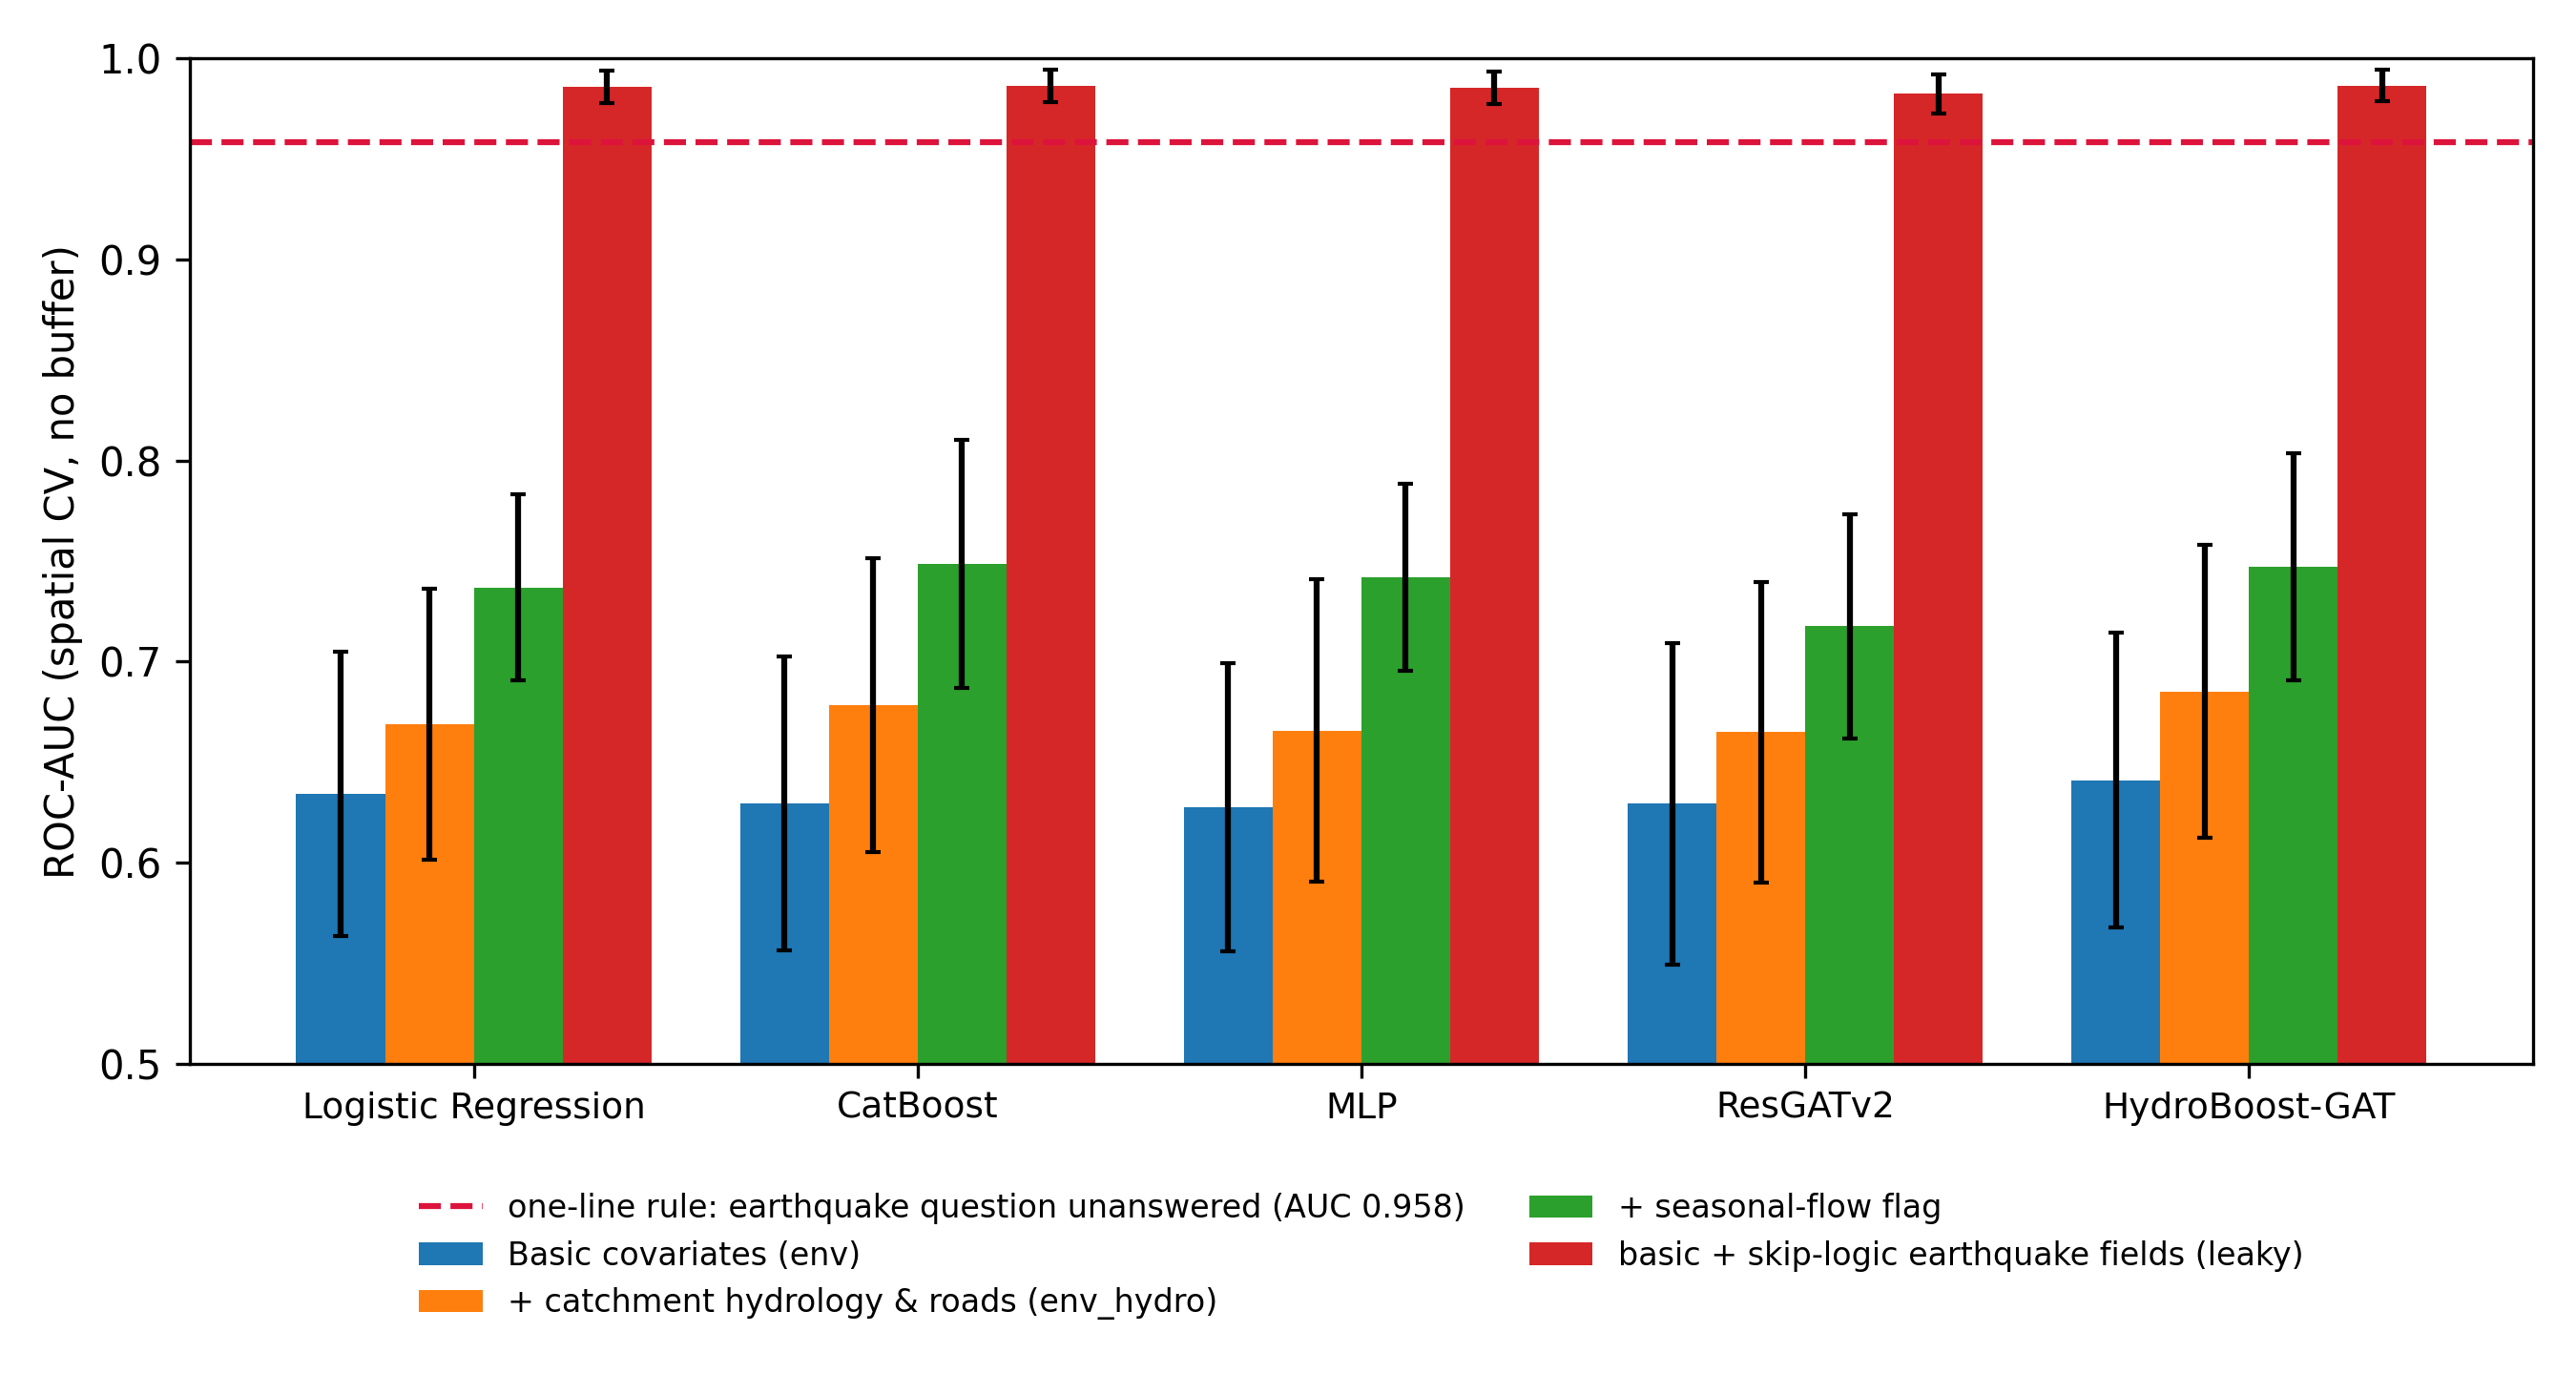

In [4]:
fig("leakage_feature_sets.png", 800)

## Benchmark (leak-free `env_hydro`)

In [5]:
s = table("benchmark_summary.csv")
view = s[s.feature_set.isin(["env_hydro"])].pivot_table(index="model", columns=["profile", "buffer_m"], values="roc_auc_mean")
view.sort_values(("main", 0.0), ascending=False)

profile                                         lomo    main        
buffer_m                                       500.0   0.0     500.0
model                                                               
HydroBoost-GAT                                0.6334  0.6852  0.6784
Random Forest                                 0.6348  0.6828  0.6809
CatBoost                                      0.6391  0.6784  0.6701
XGBoost                                          NaN  0.6722  0.6648
Logistic Regression                           0.6296  0.6689  0.6679
ResGATv2 | placebo: shuffled edge attributes     NaN  0.6661  0.6635
MLP                                           0.6162  0.6657  0.6678
ResGATv2                                      0.6141  0.6650  0.6617
ResGATv2 | placebo: random topology              NaN  0.6647  0.6624
kNN label interpolation                       0.5128  0.5976  0.5945

In [6]:
t = table("paired_tests_vs_best_tabular.csv")
t[(t.metric == "roc_auc") & (t.feature_set == "env_hydro")][["profile", "buffer_m", "model", "reference", "mean_diff", "ci95_low", "ci95_high", "p_holm"]]

,profile,buffer_m,model,reference,mean_diff,ci95_low,ci95_high,p_holm
22,lomo,500.0,Logistic Regression,CatBoost,-0.0095,-0.0469,0.0278,1.0000
23,lomo,500.0,Random Forest,CatBoost,-0.0043,-0.0313,0.0226,1.0000
24,lomo,500.0,kNN label interpolation,CatBoost,-0.1263,-0.2157,-0.0369,0.0479
25,lomo,500.0,MLP,CatBoost,-0.0229,-0.0587,0.0128,0.7847
26,lomo,500.0,ResGATv2,CatBoost,-0.0250,-0.0604,0.0104,0.7830
27,lomo,500.0,HydroBoost-GAT,CatBoost,-0.0057,-0.0301,0.0187,1.0000
42,main,0.0,Logistic Regression,Random Forest,-0.0140,-0.0466,0.0186,1.0000
43,main,0.0,XGBoost,Random Forest,-0.0106,-0.0382,0.0170,1.0000
44,main,0.0,CatBoost,Random Forest,-0.0044,-0.0254,0.0166,1.0000
45,main,0.0,kNN label interpolation,Random Forest,-0.0852,-0.1483,-0.0221,0.0715


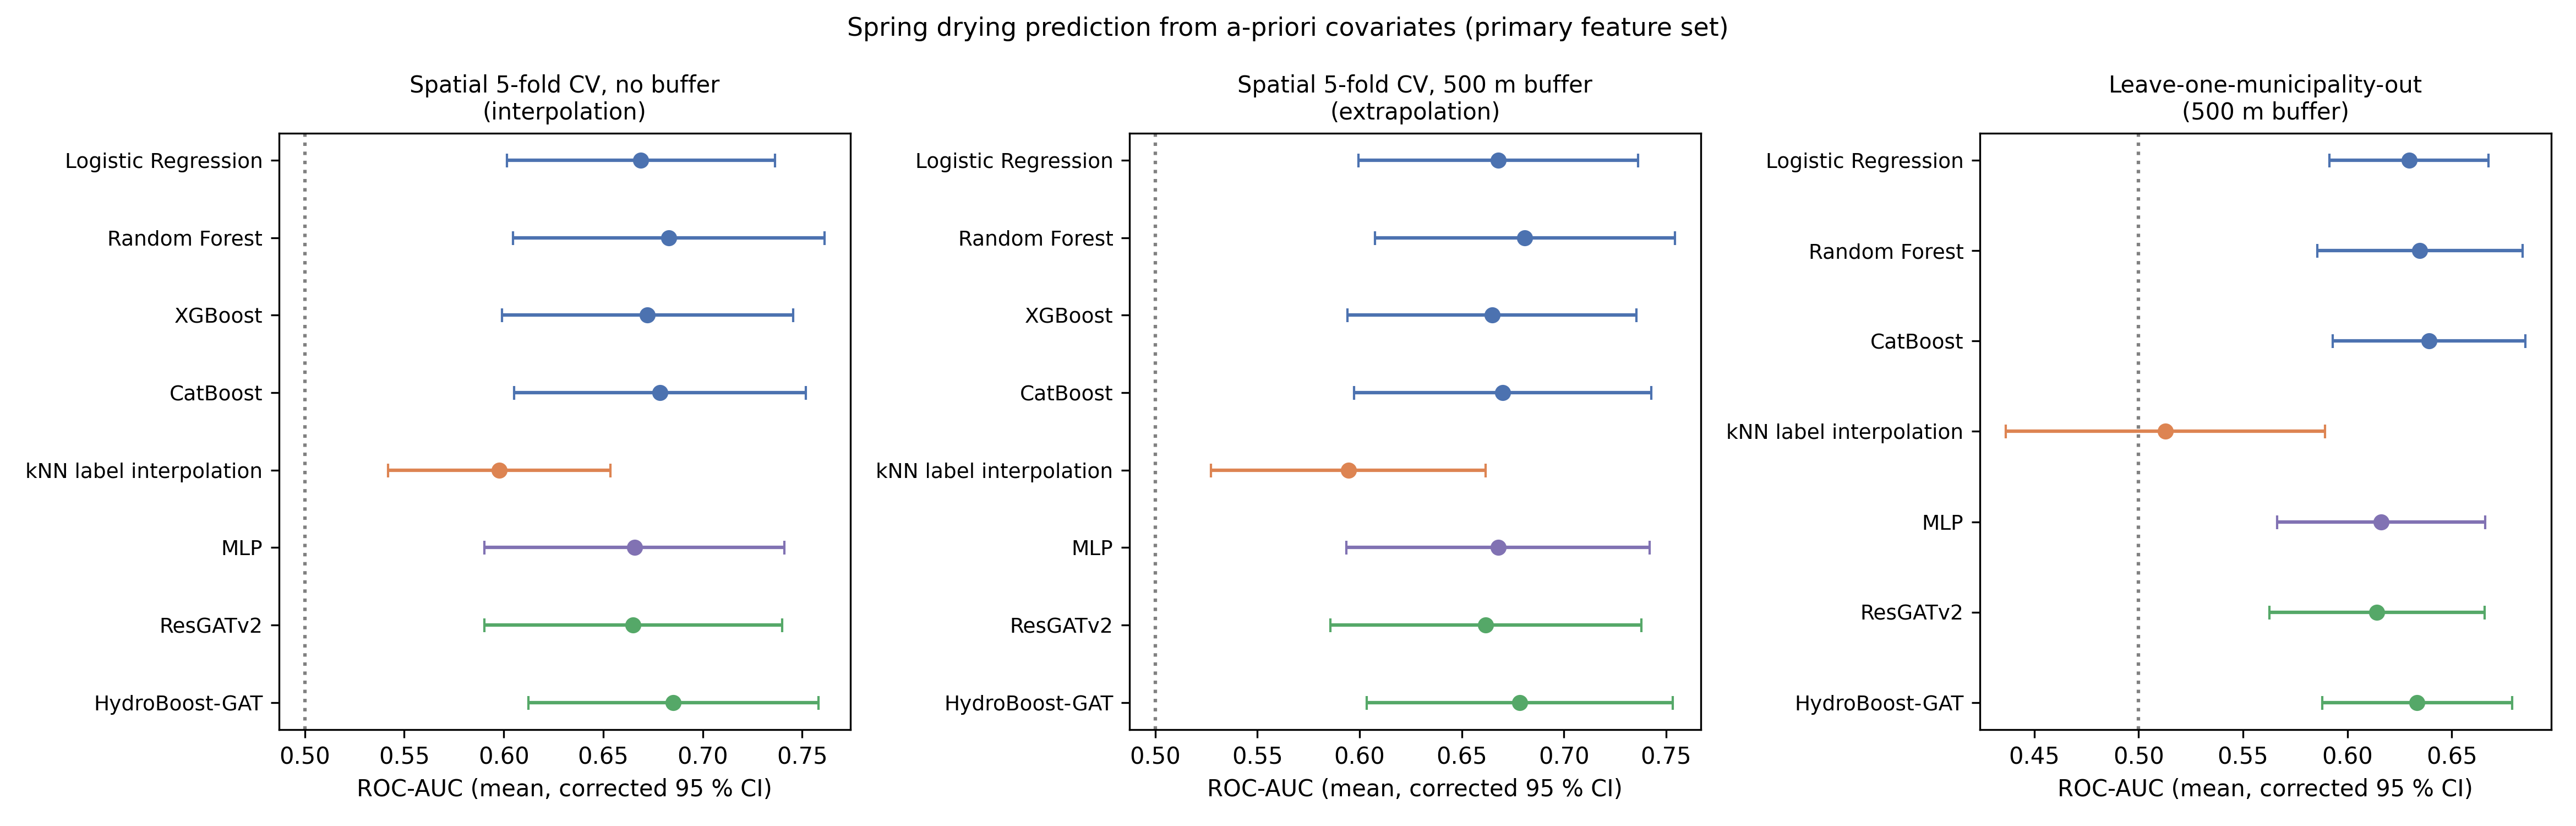

In [7]:
fig("model_benchmark_comparison.png")

## Feature-set sensitivity (spatial CV, no buffer)

In [8]:
s[(s.buffer_m == 0)].pivot_table(index="model", columns="feature_set", values="roc_auc_mean").round(3)

feature_set,env,env_hydro,env_hydro_season,env_hydro_seismic,env_rich,leaky_reference
model,,,,,,
CatBoost,0.629,0.678,0.749,0.674,0.684,0.987
HydroBoost-GAT,0.641,0.685,0.747,NaN,NaN,0.987
Logistic Regression,0.634,0.669,0.737,0.664,0.664,0.986
MLP,0.628,0.666,0.742,0.676,0.680,0.985
Random Forest,0.638,0.683,NaN,0.682,0.692,NaN
ResGATv2,0.629,0.665,0.718,NaN,NaN,0.982
ResGATv2 | placebo: random topology,0.623,0.665,NaN,NaN,NaN,NaN
ResGATv2 | placebo: shuffled edge attributes,0.629,0.666,NaN,NaN,NaN,NaN
XGBoost,0.625,0.672,NaN,0.666,0.676,NaN


## Per-municipality transfer (LOMO)

In [9]:
pd.read_csv(ROOT / "results/tables/lomo_per_municipality_auc.csv")

,Held-out municipality,N,dried,Drying rate,Logistic Regression,Random Forest,CatBoost,kNN label interpolation,MLP,ResGATv2,HydroBoost-GAT
0,Bethanchownk,385,74,19.2%,0.667,0.633,0.659,0.541,0.645,0.640,0.648
1,Dhulikhel,1174,338,28.8%,0.601,0.583,0.594,0.501,0.594,0.612,0.612
2,Namobuudha,478,96,20.1%,0.593,0.586,0.599,0.562,0.550,0.537,0.572
3,Panauti,880,83,9.4%,0.659,0.676,0.678,0.520,0.632,0.629,0.659
4,Panchkhal,1067,426,39.9%,0.622,0.672,0.660,0.623,0.633,0.645,0.654
5,Roshi RM,969,211,21.8%,0.661,0.695,0.681,0.416,0.680,0.669,0.685
6,Temal,736,293,39.8%,0.604,0.599,0.603,0.426,0.581,0.566,0.603
